In [ ]:
import gc

import numpy as np
import pandas as pd
import torch
from torch.profiler import profile, ProfilerActivity
from tqdm.auto import tqdm

from models import get_model
from equations import flops, memory

torch.backends.cudnn.benchmark = False
torch.backends.cudnn.allow_tf32 = False
torch.backends.cuda.matmul.allow_tf32 = False

torch.manual_seed(42)
rng = np.random.default_rng(42)

device = torch.device("cuda:0")
model = get_model().to(device=device, dtype=torch.float32).eval()

## Measurement grid

In [9]:
S = [32, 64, 128, 224, 256, 384, 512]
B = [1, 2, 4, 8, 16, 32, 64, 128, 256]

S_rand = rng.choice(
    sorted(set(range(32, 513, 16)) - set(S)),
    size=4, replace=False,
).tolist()

B_rand = rng.choice(
    sorted(set(range(1, 257)) - set(B)),
    size=3, replace=False,
).tolist()

grid = [
    (s, b)
    for s in sorted(B + S_rand)
    for b in sorted(B + B_rand)
]

## Benchmark

In [19]:
@torch.inference_mode()
def benchmark(s, b):
    row = {
        "S": s,
        "B": b,
        "flops": flops(s, b),
        "flops_profiler": np.nan,
        "memory_pred": memory(s, b),
        "memory": np.nan,
        "memory_baseline": np.nan,
    }

    try:
        x = torch.randn(b, 3, s, s, device=device)

        for _ in range(3):
            y = model(x)
            del y

        torch.cuda.synchronize(device)

        row["memory_baseline"] = torch.cuda.memory_allocated(device)
        torch.cuda.reset_peak_memory_stats(device)

        y = model(x)

        torch.cuda.synchronize(device)

        row["memory"] = torch.cuda.max_memory_allocated(device)
        del y

    except torch.cuda.OutOfMemoryError:
        row["memory"] = np.nan
        return row

    try:
        with profile(
            activities=[ProfilerActivity.CPU],
            record_shapes=True,
            with_flops=True,
        ) as prof:
            y = model(x)
            torch.cuda.synchronize(device)
            del y

        row["flops_profiler"] = sum(event.flops or 0 for event in prof.key_averages())

    except torch.cuda.OutOfMemoryError:
        row["flops_profiler"] = np.nan

    return row

## Evaluation

In [23]:
rows = []

for s, b in tqdm(grid):
    gc.collect()
    torch.cuda.empty_cache()

    rows.append(benchmark(s, b))

    gc.collect()
    torch.cuda.empty_cache()


  0%|          | 0/156 [00:00<?, ?it/s]

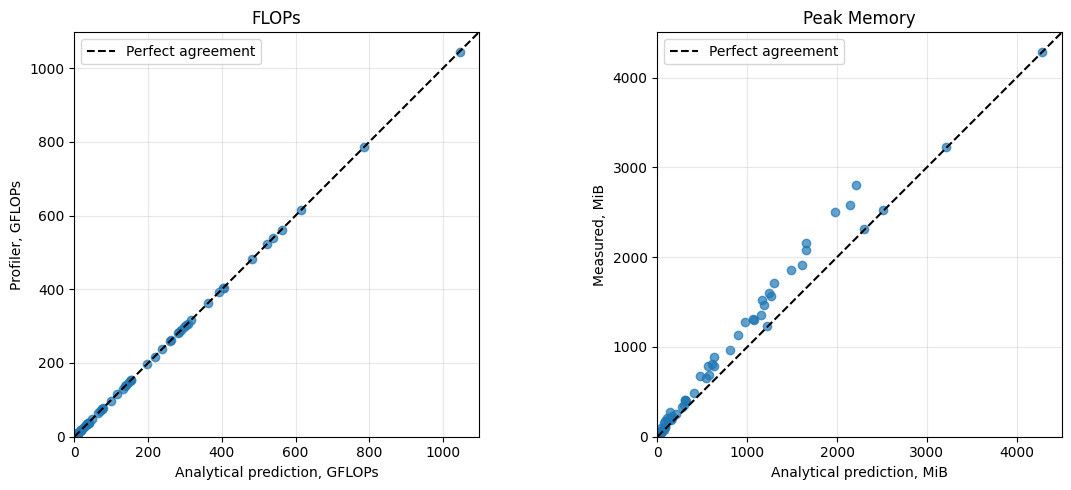

In [27]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
results = pd.DataFrame(rows)

plots = [
    ("flops", "flops_profiler", 1e9, "FLOPs", "GFLOPs"),
    ("memory_pred", "memory", 2**20, "Peak Memory", "MiB"),
]

for ax, (pred, measured, scale, title, unit) in zip(axes, plots):
    data = results[[pred, measured]].dropna()
    x = data[pred] / scale
    y = data[measured] / scale

    ax.scatter(x, y, alpha=0.7)

    limit = max(x.max(), y.max()) * 1.05
    ax.plot([0, limit], [0, limit], "k--", label="Perfect agreement")
    ax.set_xlim(0, limit)
    ax.set_ylim(0, limit)
    ax.set_aspect("equal", adjustable="box")

    ax.set_title(title)
    ax.set_xlabel(f"Analytical prediction, {unit}")
    ax.set_ylabel(f"Profiler, {unit}" if pred == "flops" else f"Measured, {unit}")
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()